# Hierarchical fitting with omissions: a worked demo

This notebook fits a hierarchical drift-diffusion model (DDM) that accounts for omissions, step by step, with `opn.hierarchical`. It is the same fit as `demo/fit_demo.py`, with plots of the data and the results added.

**The data** (`demo/demo_data.csv`) are 6 simulated participants with 200 trials each, in an easy and a hard condition. Each trial had a response deadline of 1.5 s, and about 19 % of trials got no response before it (omissions). The data were simulated from the model fitted here (`demo/make_demo_data.py`), so the estimates can be compared with the true values (`demo/demo_truth.csv`).

**Why model omissions?** A deadline cuts off the slowest responses. Fitting only the answered trials treats a truncated RT distribution as if it were complete, which biases the estimates (e.g. it makes responses look faster and boundaries lower than they are). Here, answered trials are scored by a LAN (choice and RT) and omitted trials by the omission network (probability of no response before the deadline), so both kinds of trial inform the estimates.

**Running time.** The full fit (4 chains × 1000 tuning + 1000 draws) takes about half an hour on 4 CPUs. Section 4 reuses the fit saved in `demo/output/` by `make demo` if it exists; set `REFIT = True` there to fit again, or lower `draws` and `tune` for a quick try.

**Running the notebook.** The container includes JupyterLab: `apptainer exec --bind "$PWD" opn.sif jupyter lab --no-browser --port 8888` from the repository root, then open this file. `make notebook` runs it without a browser. The plain Python environment from the README works too.

## Setup

JAX must be given one CPU device per chain before it starts, so `opn.set_cpu_devices` comes first. The networks are float32, so PyTensor is set to float32 before any model is built.

In [1]:
import json
import os
import sys
from dataclasses import asdict

# Make the opn package importable: find the repository root from the notebook's folder
REPO_ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(REPO_ROOT, "src", "opn")):
    parent_dir = os.path.dirname(REPO_ROOT)
    if parent_dir == REPO_ROOT:
        raise RuntimeError("start the notebook from inside the opn repository")
    REPO_ROOT = parent_dir
sys.path.insert(0, os.path.join(REPO_ROOT, "src"))

import opn
opn.set_cpu_devices(4)                # one CPU device per chain; must run before JAX starts

import pytensor
pytensor.config.floatX = "float32"    # the networks are float32; set before building the model

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit

from opn import hierarchical as hier
from opn.simulate import simulate

%matplotlib inline
DEMO_DIR = os.path.join(REPO_ROOT, "demo")

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


## 1. Look at the data

One row per trial. `rt` is empty when no response was recorded before the deadline; `choice` is 1 for the upper and 0 for the lower boundary.

In [2]:
trial_table = pd.read_csv(os.path.join(DEMO_DIR, "demo_data.csv"))
trial_table.head(8)

,participant,trial,difficulty,rt,choice
0,P01,1,hard,0.7432,0.0
1,P01,2,easy,0.6439,1.0
2,P01,3,easy,0.5053,1.0
3,P01,4,easy,1.4105,1.0
4,P01,5,hard,0.9192,0.0
5,P01,6,easy,NaN,NaN
6,P01,7,hard,0.9310,1.0
7,P01,8,hard,0.6582,0.0


In [3]:
overview = (trial_table.assign(omitted=trial_table["rt"].isna())
            .groupby(["participant", "difficulty"])
            .agg(trials=("trial", "size"), omission_rate=("omitted", "mean"),
                 mean_rt=("rt", "mean"), upper_choice_rate=("choice", "mean")))
overview.round(3)

trials  omission_rate  mean_rt  upper_choice_rate
participant difficulty                                                   
P01         easy           100           0.18    0.853              0.939
            hard           100           0.30    0.858              0.686
P02         easy           100           0.10    0.846              0.944
            hard           100           0.30    0.864              0.771
P03         easy           100           0.11    0.772              0.865
            hard           100           0.19    0.916              0.556
P04         easy           100           0.25    0.817              0.827
            hard           100           0.30    0.802              0.314
P05         easy           100           0.11    0.863              0.685
            hard           100           0.18    0.891              0.317
P06         easy           100           0.09    0.780              0.956
            hard           100           0.17    0.880              0.831

Hard trials are slower, have more omissions and fewer upper-boundary choices. The RT distributions are cut off at the deadline (dashed line): the omitted trials are the missing right tail.

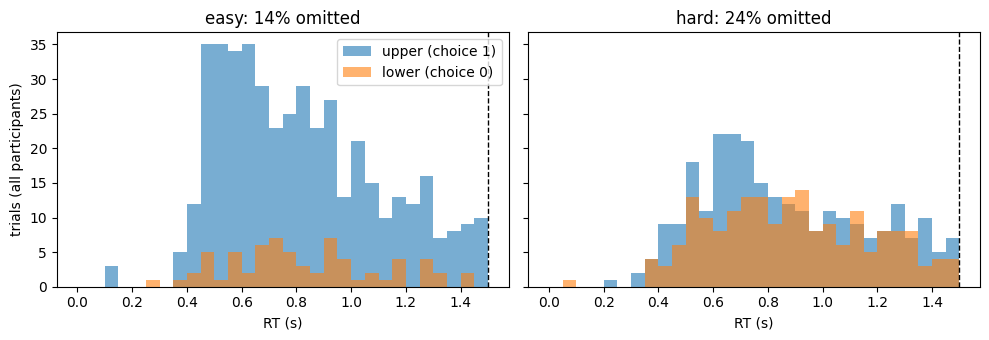

In [4]:
DEADLINE = 1.5
rt_bins = np.linspace(0, DEADLINE, 31)
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for axis, level in zip(axes, ["easy", "hard"]):
    condition_trials = trial_table[trial_table["difficulty"] == level]
    for choice, label in [(1, "upper (choice 1)"), (0, "lower (choice 0)")]:
        axis.hist(condition_trials.loc[condition_trials["choice"] == choice, "rt"], bins=rt_bins,
                  alpha=0.6, label=label)
    axis.axvline(DEADLINE, color="black", linestyle="--", linewidth=1)
    axis.set_title(f"{level}: {condition_trials['rt'].isna().mean():.0%} omitted")
    axis.set_xlabel("RT (s)")
axes[0].set_ylabel("trials (all participants)")
axes[0].legend()
figure.tight_layout()

## 2. Prepare the data

`prepare_data` checks the table and codes it for the model:

- a trial is omitted if its RT is missing or at least the deadline (an optional true/false column could also mark omissions);
- responses coded 0/1 are recoded to −1/+1;
- the two-level text column `difficulty` becomes −1/+1, in alphabetical order (easy = −1, hard = +1);
- participants are numbered in order of first appearance.

It raises an error before any sampling if a column is missing or coded unexpectedly.

In [5]:
COLUMNS = dict(subject="participant", rt="rt", response="choice")
data = hier.prepare_data(trial_table, DEADLINE, **COLUMNS, predictors=["difficulty"])

print(f"{len(data.subjects)} participants, {len(data.trials)} trials, {data.n_omitted} omitted "
      f"({data.n_omitted / len(data.trials):.1%})")
print("participants:", data.subjects)
print("coding of text predictors:", data.coding)
data.trials.head()

6 participants, 1200 trials, 228 omitted (19.0%)
participants: ['P01', 'P02', 'P03', 'P04', 'P05', 'P06']
coding of text predictors: {'difficulty': {'easy': -1.0, 'hard': 1.0}}


,subject,rt,response,omitted,difficulty
0,0,0.7432,-1.0,False,1.0
1,0,0.6439,1.0,False,-1.0
2,0,0.5053,1.0,False,-1.0
3,0,1.4105,1.0,False,-1.0
4,0,0.9192,-1.0,False,1.0


## 3. Specify the model

`ModelSpec` says what to fit:

- `model="ddm"`: drift `v`, boundary `a`, starting point `z` and non-decision time `t`;
- `fixed={"z": 0.5}`: unbiased starting point, not estimated;
- `regressions={"v": ["difficulty"]}`: drift depends on difficulty.

Each estimated parameter (and the lapse probability `p_lapse`) has a group mean `<p>_mu` and a group spread `<p>_sigma` on an unbounded scale. Participant values are `<p>_subj = <p>_mu + <p>_sigma * <p>_offset` (non-centred, which samples well with few participants). The difficulty effect has a group mean `v_difficulty_mu` and, with random slopes (the default), participant values `v_difficulty_subj`. On every trial the unbounded value is mapped into the parameter's range with a scaled sigmoid:

In [6]:
SPEC = hier.ModelSpec(
    model="ddm",
    fixed={"z": 0.5},                    # unbiased starting point
    regressions={"v": ["difficulty"]},   # drift depends on difficulty (easy = -1, hard = +1)
)
print("estimated per participant:", SPEC.free_params)
pd.DataFrame(SPEC.param_bounds(), index=["lower", "upper"]).T

estimated per participant: ['v', 'a', 't', 'p_lapse']


,lower,upper
v,-3.0,3.00
a,0.3,2.50
t,0.0,2.00
p_lapse,0.0,0.05


`build_model` turns data and specification into a PyMC model. `fit` (next section) does this itself; building it here shows the variables and checks that the model evaluates.

In [7]:
model = hier.build_model(data, SPEC)
initial_point = model.initial_point()
for random_variable in model.free_RVs:
    value_name = model.rvs_to_values[random_variable].name
    print(f"{random_variable.name:24s} shape {initial_point[value_name].shape}")
print(f"\nlog-probability at the starting point: {float(model.compile_logp()(initial_point)):.1f}")

/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


v_mu                     shape ()
v_sigma                  shape ()
v_offset                 shape (6,)
v_difficulty_mu          shape ()
v_difficulty_sigma       shape ()
v_difficulty_offset      shape (6,)
a_mu                     shape ()
a_sigma                  shape ()
a_offset                 shape (6,)
t_mu                     shape ()
t_sigma                  shape ()
t_offset                 shape (6,)
p_lapse_mu               shape ()
p_lapse_sigma            shape ()
p_lapse_offset           shape (6,)

log-probability at the starting point: -4145.6


## 4. Fit

`hier.fit` builds the model, runs NUTS (NumPyro, chains in parallel), saves `posterior.nc`, `summary.csv` and `fit_info.json` to `FIT_DIR`, and prints the group-level estimates and diagnostics. Here it runs only if `FIT_DIR` holds no fit yet, or if `REFIT = True`.

In [8]:
SAMPLING = dict(chains=4, draws=1000, tune=1000, target_accept=0.95, seed=1)
FIT_DIR = os.path.join(DEMO_DIR, "output")
REFIT = False      # True: fit again even if FIT_DIR already holds a fit (about half an hour on 4 CPUs)

if REFIT or not os.path.isfile(os.path.join(FIT_DIR, "posterior.nc")):
    idata = hier.fit(data, SPEC, FIT_DIR, **SAMPLING)
else:
    idata = az.from_netcdf(os.path.join(FIT_DIR, "posterior.nc"))
    print(f"Loaded the saved fit from {os.path.relpath(FIT_DIR, REPO_ROOT)} (set REFIT = True to fit again)")

with open(os.path.join(FIT_DIR, "fit_info.json")) as info_file:
    fit_info = json.load(info_file)
print("sampling settings of this fit:", fit_info["sampling"])
if fit_info["model"] != json.loads(json.dumps(asdict(SPEC))):
    print("WARNING: the saved fit used a different model specification:", fit_info["model"])

Compiling...


Data: 6 subjects, 1200 trials, 228 omitted (19.0%) at deadline 1.5 s
  predictor difficulty: easy = -1, hard = +1
Model: ddm; estimated per subject: v, a, t, p_lapse; fixed: {'z': 0.5}; condition effects: {'v': ['difficulty']}


Compilation time = 0:00:02.384255
Sampling...
/usr/local/lib/python3.11/site-packages/jax/_src/numpy/array_methods.py:66: UserWarning: Explicitly requested dtype float64 requested in astype is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.
  return lax_numpy.astype(arr, dtype)
Sampling time = 0:31:33.660868
Transforming variables...
Transformation time = 0:00:00.382616



Group-level estimates (natural scale; condition effects on the unbounded scale):
                     mean     sd  hdi_3%  hdi_97%  r_hat
v_difficulty_mu    -0.332  0.036  -0.395   -0.258   1.00
v_mu_natural        0.651  0.229   0.188    1.053   1.01
a_mu_natural        0.969  0.043   0.891    1.053   1.00
t_mu_natural        0.297  0.014   0.271    0.324   1.00
p_lapse_mu_natural  0.026  0.008   0.013    0.041   1.00

Diagnostics: max R-hat 1.010, min bulk ESS 1080, min tail ESS 1263, divergences 0

Saved to demo/output
sampling settings of this fit: {'chains': 4, 'draws': 1000, 'tune': 1000, 'target_accept': 0.95, 'seed': 1}


## 5. Check convergence

Before reading any estimate, check that the chains agree and have enough effective draws:

- **R-hat** should be at most 1.01 for every parameter;
- **ESS** (effective sample size, bulk and tail) should be at least 400;
- **divergent transitions** should be absent or few and scattered. If there are many, raise `target_accept` (e.g. to 0.99) and check that the estimates do not change.

In [9]:
summary = hier.summarize(idata)
diagnostic_values = hier.diagnostics(summary, idata)
print(diagnostic_values)
for problem in hier.convergence_problems(diagnostic_values):
    print("WARNING:", problem)

{'max_r_hat': 1.01, 'min_ess_bulk': 1080.0, 'min_ess_tail': 1263.0, 'divergences': 0}


Trace plots of the group-level parameters: the chains (one line each) should overlap and look like stationary noise.

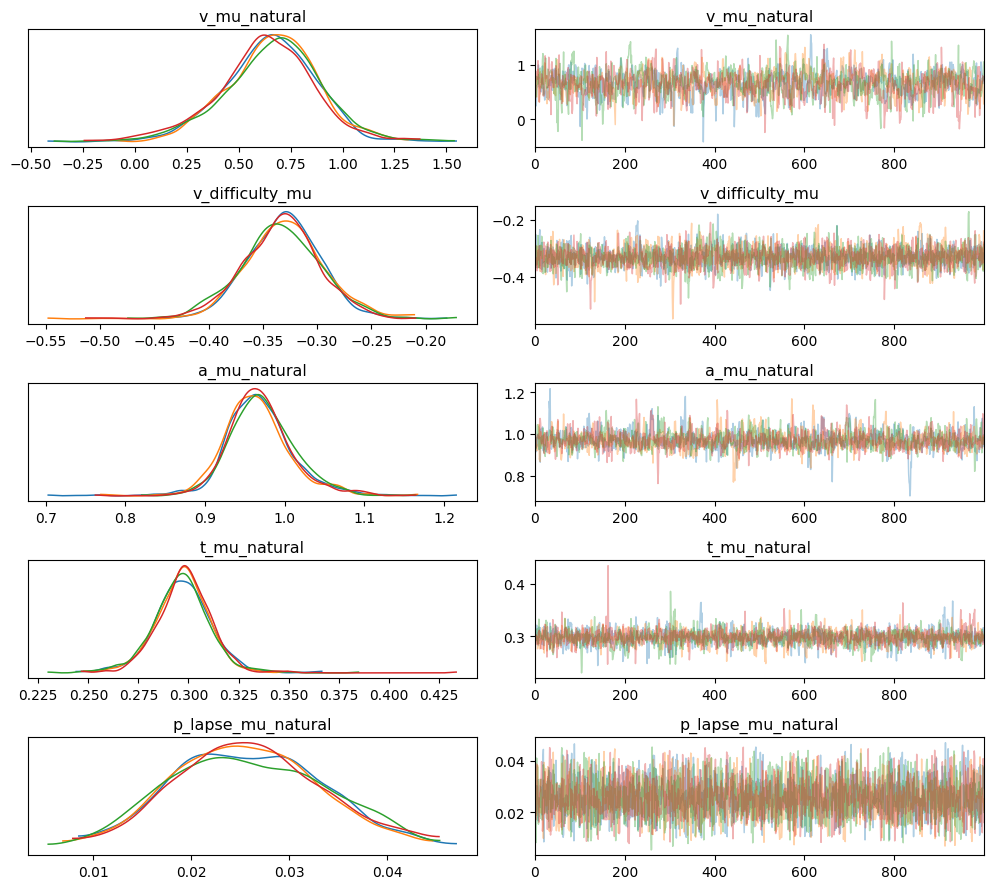

In [10]:
GROUP_PARAMETERS = ["v_mu_natural", "v_difficulty_mu", "a_mu_natural", "t_mu_natural", "p_lapse_mu_natural"]
az.plot_trace(idata, var_names=GROUP_PARAMETERS, compact=False, figsize=(10, 9))
plt.tight_layout()

Divergences concentrated in one region of a pair plot point to a geometry the sampler cannot handle; a few isolated ones are usually harmless. Group spreads (`_sigma`) are the usual suspects in hierarchical models:

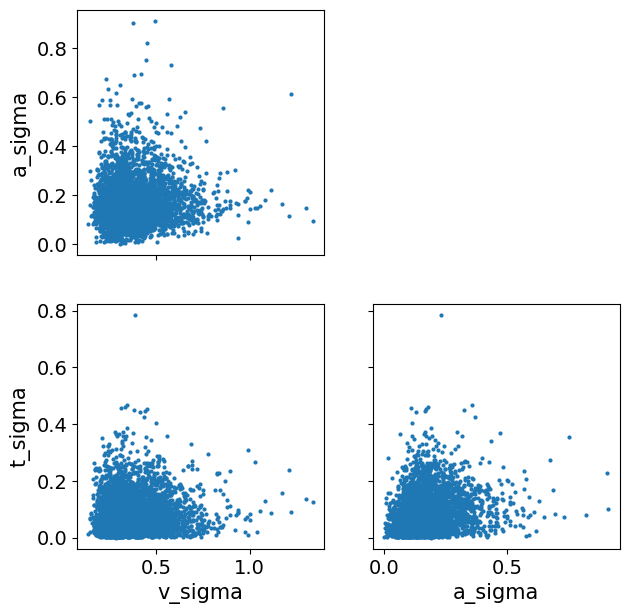

In [11]:
az.plot_pair(idata, var_names=["v_sigma", "a_sigma", "t_sigma"], divergences=True, figsize=(7, 7));

## 6. Group-level estimates

`<p>_mu_natural` is the group mean on the parameter's own scale, with all predictors at 0 (here: midway between easy and hard). The difficulty effect `v_difficulty_mu` acts on the unbounded scale: negative means lower drift on hard trials.

In [12]:
summary.loc[GROUP_PARAMETERS, ["mean", "sd", "hdi_3%", "hdi_97%", "ess_bulk", "r_hat"]]

,mean,sd,hdi_3%,hdi_97%,ess_bulk,r_hat
v_mu_natural,0.651,0.229,0.188,1.053,1223.0,1.01
v_difficulty_mu,-0.332,0.036,-0.395,-0.258,2385.0,1.00
a_mu_natural,0.969,0.043,0.891,1.053,1532.0,1.00
t_mu_natural,0.297,0.014,0.271,0.324,2473.0,1.00
p_lapse_mu_natural,0.026,0.008,0.013,0.041,4283.0,1.00


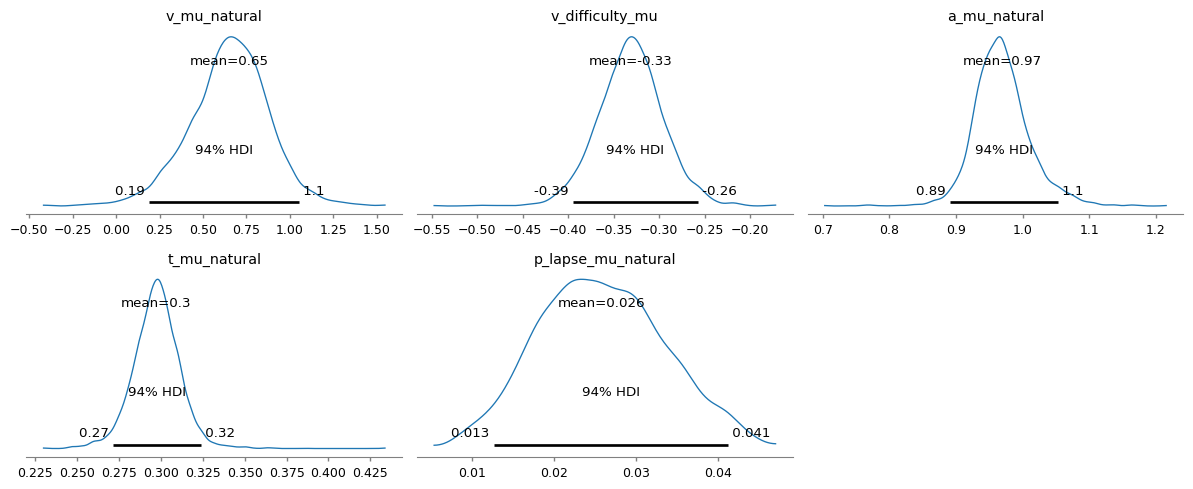

In [13]:
az.plot_posterior(idata, var_names=GROUP_PARAMETERS, hdi_prob=0.94, figsize=(12, 5), textsize=9)
plt.tight_layout()

To read a condition effect on the parameter's own scale, transform `group mean + code × effect` for each condition. A parameter on a given trial is `low + (high − low) · sigmoid(unbounded value)`, with `(low, high)` its range from `fit_info.json`:

P(drift on hard trials < drift on easy trials) = 1.000


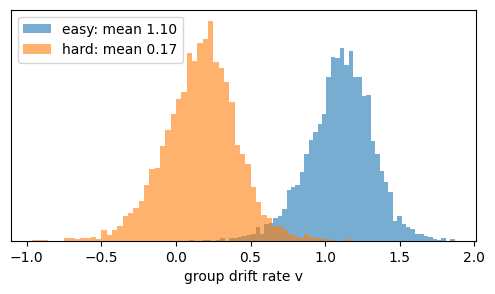

In [14]:
posterior = idata.posterior
parameter_bounds = fit_info["parameter_bounds"]


def to_range(unbounded_value, name):
    low, high = parameter_bounds[name]
    return low + (high - low) * expit(unbounded_value)


difficulty_coding = fit_info["predictor_coding"]["difficulty"]      # {"easy": -1.0, "hard": 1.0}
group_drift = {level: to_range(posterior["v_mu"] + code * posterior["v_difficulty_mu"], "v")
               for level, code in difficulty_coding.items()}

figure, axis = plt.subplots(figsize=(6, 3))
for level, drift_draws in group_drift.items():
    axis.hist(drift_draws.values.ravel(), bins=60, alpha=0.6, label=f"{level}: mean {float(drift_draws.mean()):.2f}")
axis.set_xlabel("group drift rate v")
axis.set_yticks([])
axis.legend()
probability_lower = float((group_drift["hard"] < group_drift["easy"]).mean())
print(f"P(drift on hard trials < drift on easy trials) = {probability_lower:.3f}")

## 7. Participant estimates compared with the truth

Since the data were simulated, the participant-level estimates can be checked against the values they were simulated from. `<p>_subj_natural` holds each participant's value on the parameter's own scale; the drift per condition again combines the participant's drift and difficulty effect. (This is what `demo/check_recovery.py` does.)

In [15]:
truth = pd.read_csv(os.path.join(DEMO_DIR, "demo_truth.csv")).set_index("participant")

# Posterior draws on the natural scale, with dimensions (chain, draw, subject)
natural_draws = {f"v_{level}": to_range(posterior["v_subj"] + code * posterior["v_difficulty_subj"], "v")
                 for level, code in difficulty_coding.items()}
natural_draws.update({"a": posterior["a_subj_natural"], "t": posterior["t_subj_natural"],
                      "p_lapse": posterior["p_lapse_subj_natural"]})

recovery_rows = []
for subject_index, subject in enumerate(fit_info["subjects"]):
    for name, parameter_draws in natural_draws.items():
        samples = parameter_draws.isel(subject=subject_index).values.ravel()
        hdi_low, hdi_high = az.hdi(samples, hdi_prob=0.94)
        true_value = truth.loc[subject, name]
        recovery_rows.append({"participant": subject, "parameter": name, "true": true_value,
                              "estimate": samples.mean(), "hdi_3%": hdi_low, "hdi_97%": hdi_high,
                              "covered": hdi_low <= true_value <= hdi_high})
recovery = pd.DataFrame(recovery_rows)

per_parameter = recovery.groupby("parameter", sort=False).apply(
    lambda parameter_rows: pd.Series({"correlation": np.corrcoef(parameter_rows["true"], parameter_rows["estimate"])[0, 1],
                                      "covered": f"{parameter_rows['covered'].sum()}/{len(parameter_rows)}"}))
print(f"{recovery['covered'].sum()}/{len(recovery)} true values inside the 94% HDI")
per_parameter.round(2)

26/30 true values inside the 94% HDI


,correlation,covered
parameter,,
v_easy,0.90,5/6
v_hard,0.97,6/6
a,0.68,5/6
t,0.45,4/6
p_lapse,0.09,6/6


Each point is one participant: the posterior mean with its 94 % HDI against the true value. Points on the diagonal are recovered exactly.

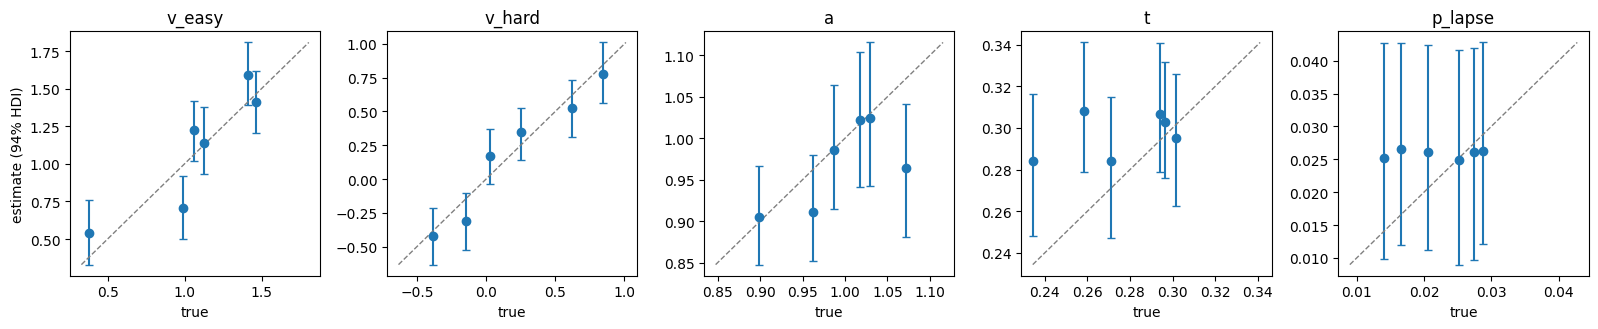

In [16]:
figure, axes = plt.subplots(1, len(natural_draws), figsize=(16, 3.4))
for axis, (name, parameter_rows) in zip(axes, recovery.groupby("parameter", sort=False)):
    axis.errorbar(parameter_rows["true"], parameter_rows["estimate"],
                  yerr=[parameter_rows["estimate"] - parameter_rows["hdi_3%"],
                        parameter_rows["hdi_97%"] - parameter_rows["estimate"]],
                  fmt="o", capsize=3)
    axis_limits = [min(parameter_rows["true"].min(), parameter_rows["hdi_3%"].min()),
                   max(parameter_rows["true"].max(), parameter_rows["hdi_97%"].max())]
    axis.plot(axis_limits, axis_limits, color="grey", linestyle="--", linewidth=1)
    axis.set_title(name)
    axis.set_xlabel("true")
axes[0].set_ylabel("estimate (94% HDI)")
figure.tight_layout()

Drift rates are recovered closely. Boundary and non-decision time less so: with only 6 participants, their estimates are pulled toward the group mean (shrinkage), which is how a hierarchical model trades a little bias for much more stable estimates. The lapse probability is small (1–3 %) and barely identified per participant; its group mean is the more useful number.

## 8. Posterior predictive check: omissions and RTs

A model that accounts for omissions should reproduce how many trials each participant omits in each condition. For 100 posterior draws, the code below simulates each participant's trials in each condition from the fitted parameters (including lapses, which always respond before the deadline). It then compares the predicted omission rate and mean RT of answered trials with the data.

observed omission rates inside the 94% predictive interval: 11/12
observed mean RTs inside the 94% predictive interval: 11/12


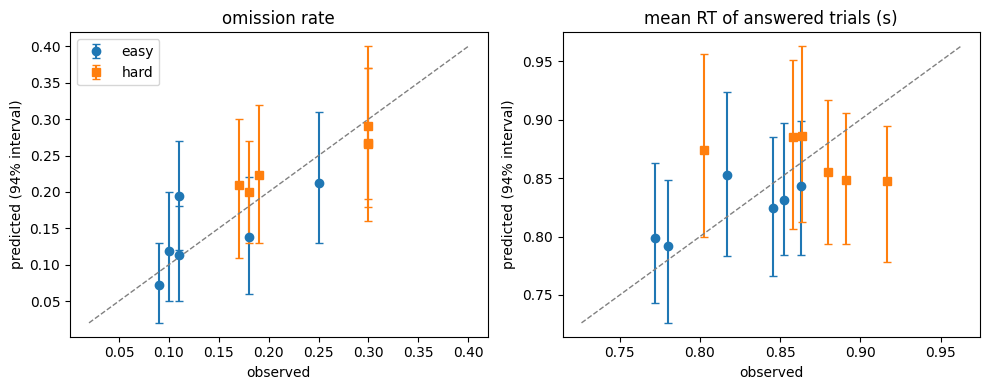

In [17]:
rng = np.random.default_rng(1)
N_PREDICTIVE_DRAWS = 100
draws_by_subject = {name: parameter_draws.stack(sample=("chain", "draw")).transpose("subject", "sample").values
                    for name, parameter_draws in natural_draws.items()}
draw_indices = rng.choice(draws_by_subject["a"].shape[1], N_PREDICTIVE_DRAWS, replace=False)

check_rows = []
for subject_index, subject in enumerate(fit_info["subjects"]):
    for level in difficulty_coding:
        observed = trial_table[(trial_table["participant"] == subject) & (trial_table["difficulty"] == level)]
        predicted_omission_rates, predicted_mean_rts = [], []
        for draw in draw_indices:
            v, a, t, p_lapse = (draws_by_subject[name][subject_index, draw] for name in (f"v_{level}", "a", "t", "p_lapse"))
            simulated = simulate("ddm", [v, a, SPEC.fixed["z"], t], len(observed), random_state=int(rng.integers(2**31)))
            is_lapse = rng.random(len(observed)) < p_lapse
            rts = np.where(is_lapse, rng.uniform(0, DEADLINE, len(observed)), simulated[:, 0])
            answered = rts < DEADLINE
            predicted_omission_rates.append(1 - answered.mean())
            predicted_mean_rts.append(rts[answered].mean())
        check_rows.append({"participant": subject, "difficulty": level,
                           "observed_omission_rate": observed["rt"].isna().mean(),
                           "predicted_omission_rate": np.mean(predicted_omission_rates),
                           "omission_rate_low": np.percentile(predicted_omission_rates, 3),
                           "omission_rate_high": np.percentile(predicted_omission_rates, 97),
                           "observed_mean_rt": observed["rt"].mean(),
                           "predicted_mean_rt": np.mean(predicted_mean_rts),
                           "mean_rt_low": np.percentile(predicted_mean_rts, 3),
                           "mean_rt_high": np.percentile(predicted_mean_rts, 97)})
predictive_check = pd.DataFrame(check_rows)
for statistic, label in [("omission_rate", "omission rates"), ("mean_rt", "mean RTs")]:
    inside = predictive_check[f"observed_{statistic}"].between(predictive_check[f"{statistic}_low"],
                                                               predictive_check[f"{statistic}_high"])
    print(f"observed {label} inside the 94% predictive interval: {inside.sum()}/{len(inside)}")

figure, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, statistic, label in [(axes[0], "omission_rate", "omission rate"), (axes[1], "mean_rt", "mean RT of answered trials (s)")]:
    for level, marker in zip(difficulty_coding, ["o", "s"]):
        level_rows = predictive_check[predictive_check["difficulty"] == level]
        axis.errorbar(level_rows[f"observed_{statistic}"], level_rows[f"predicted_{statistic}"],
                      yerr=[level_rows[f"predicted_{statistic}"] - level_rows[f"{statistic}_low"],
                            level_rows[f"{statistic}_high"] - level_rows[f"predicted_{statistic}"]],
                      fmt=marker, capsize=3, label=level)
    axis_limits = [predictive_check[[f"observed_{statistic}", f"{statistic}_low"]].min().min(),
                   predictive_check[[f"observed_{statistic}", f"{statistic}_high"]].max().max()]
    axis.plot(axis_limits, axis_limits, color="grey", linestyle="--", linewidth=1)
    axis.set_title(label)
    axis.set_xlabel("observed")
    axis.set_ylabel("predicted (94% interval)")
axes[0].legend()
figure.tight_layout()

Each point is one participant in one condition; on the dashed diagonal, prediction and data agree. The predicted omission rates follow the observed ones: more omissions on hard trials, and the differences between participants. Mean RTs of answered trials differ little between participants (about 0.77–0.92 s), so that panel is noisier: the model gets the overall level and the slowing on hard trials, not every participant's exact mean. Count how many observed values fall inside their intervals (printed above) rather than judging by eye.

## Fitting your own data

- Copy `demo/fit_demo.py` (e.g. to `scripts/hierarchical/fit_my_study.py`) and edit its definition section: data file, deadline, column names, `ModelSpec`, sampling settings. The script runs the same steps as sections 2–4. Run it on a few participants with short chains first, then the full fit on a cluster.
- Or adapt this notebook: change `trial_table`, `DEADLINE`, `COLUMNS` and `SPEC`.
- The README section *Hierarchical fitting* explains every option, the output files, and how to extend the model.